## Generate & Load the Relatable NIC Grievance Dataset

In [ ]:
#Install relevant library
!pip install seaborn

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Set random seed for reproducibility
np.random.seed(99)
n_samples = 400

# Generate realistic public grievance attributes
text_len = np.random.randint(60, 1200, size=n_samples)
urgency_score = np.random.uniform(0.0, 10.0, size=n_samples)
prior_filings = np.random.poisson(lam=0.4, size=n_samples)
days_pending = np.random.exponential(scale=6.0, size=n_samples).round(1)
dept_code = np.random.choice([1, 2, 3, 4, 5], size=n_samples, p=[0.40, 0.20, 0.20, 0.10, 0.10])

# Target Label: 0 = Routine / Normal Grievance, 1 = Urgent / Ministerial Escalation Needed
score_logistic = -5.2 + 0.45 * urgency_score + 1.2 * np.where(dept_code == 2, 1.0, 0.0) + 0.05 * days_pending
prob = 1 / (1 + np.exp(-score_logistic))
is_urgent = (np.random.random(n_samples) < prob).astype(int)

df = pd.DataFrame({
    'Grievance_ID': [f"GRV-{2026}-{4000+i}" for i in range(n_samples)],
    'Department_ID': dept_code,
    'Text_Length': text_len,
    'Urgency_Keyword_Score': np.round(urgency_score, 1),
    'Citizen_Prior_Filings': prior_filings,
    'Days_Pending': days_pending,
    'Is_High_Priority': is_urgent
})

# Introduce realistic missing values (messy data)
df.loc[14, 'Urgency_Keyword_Score'] = np.nan
df.loc[77, 'Days_Pending'] = np.nan

# Save to CSV
df.to_csv('nic_grievance_data.csv', index=False)
print("✅ Dataset generated and saved as 'nic_grievance_data.csv'. Total records:", len(df))
df.head(8)

## Inspect Data, Check Missing Values & Class Imbalance

In [ ]:
# 1. Load data
df_grievance = pd.read_csv('nic_grievance_data.csv')

# 2. Check for missing values
print("--- Missing Values ---")
print(df_grievance.isnull().sum())

In [ ]:
# Clean missing values using median imputation
df_grievance['Urgency_Keyword_Score'] = df_grievance['Urgency_Keyword_Score'].fillna(df_grievance['Urgency_Keyword_Score'].median())
df_grievance['Days_Pending'] = df_grievance['Days_Pending'].fillna(df_grievance['Days_Pending'].median())

# 3. Check Class Imbalance
print("\n--- Target Class Distribution (0 = Routine, 1 = Urgent) ---")
counts = df_grievance['Is_High_Priority'].value_counts()
print(counts)

In [ ]:
print((df_grievance['Is_High_Priority'].value_counts(normalize=True) * 100).round(1), "%")

Notice that ~85% of grievances are routine (0) and only ~15% require urgent escalation (1). This real-world imbalance highlights why we need proper evaluation metrics beyond raw accuracy.

## Feature Selection & Train/Test Split

In [6]:
from sklearn.model_selection import train_test_split

# Define Features (X) and Target Label (y)
features = ['Department_ID', 'Text_Length', 'Urgency_Keyword_Score', 'Citizen_Prior_Filings', 'Days_Pending']
X = df_grievance[features]
y = df_grievance['Is_High_Priority']

# Split: 80% Training (Study Material), 20% Testing (Exam)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape[0]} grievances")
print(f"Testing set size : {X_test.shape[0]} grievances")

Training set size: 320 grievances
Testing set size : 80 grievances


## Train a Classification Model (Random Forest Classifier)
(Using Random Forest instead of Logistic Regression gives exposure to a robust, tree-based ensemble model commonly used in e-governance analytics).

In [7]:
from sklearn.ensemble import RandomForestClassifier

# Initialize and train the classifier
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

print("🎯 Model training completed successfully!")

🎯 Model training completed successfully!


## Evaluate Predictions & Visualize with Seaborn (Confusion Matrix)

Overall Test Accuracy: 81.25%

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.84      0.96      0.90        68
           1       0.00      0.00      0.00        12

    accuracy                           0.81        80
   macro avg       0.42      0.48      0.45        80
weighted avg       0.72      0.81      0.76        80



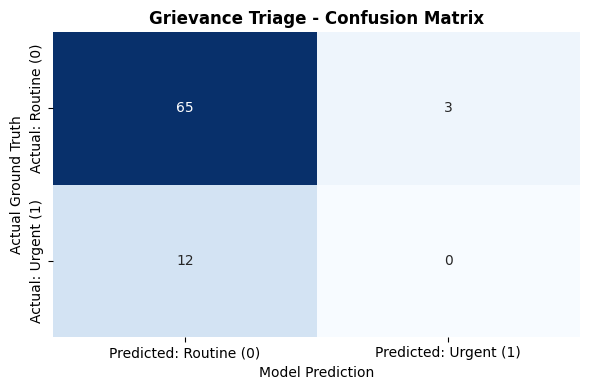

In [8]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Predict on unseen test data
y_pred = model.predict(X_test)

# Calculate accuracy
acc = accuracy_score(y_test, y_pred)
print(f"Overall Test Accuracy: {acc * 100:.2f}%\n")

# Detailed Classification Report
print("--- Classification Report ---")
print(classification_report(y_test, y_pred))

# Plot Confusion Matrix using Seaborn
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted: Routine (0)', 'Predicted: Urgent (1)'],
            yticklabels=['Actual: Routine (0)', 'Actual: Urgent (1)'])
plt.title('Grievance Triage - Confusion Matrix', fontsize=12, fontweight='bold')
plt.xlabel('Model Prediction')
plt.ylabel('Actual Ground Truth')
plt.tight_layout()
plt.show()